In [ ]:
import numpy as np

## Part 1: PCA by hand

In [12]:
x1 = np.array([-2, -1, 0, 1, 2])
x2 = np.array([-1, 0, 1, 2, 3])
X = np.column_stack([x1, x2]).astype(float)

mu = X.mean(axis=0)
Xc = X - mu

U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
w = Vt[0]
print("mean:", mu)
print("first PC:", w)

mean: [0. 1.]
first PC: [0.70710678 0.70710678]


In [13]:
def recon_error(p):
    z = np.array(p, dtype=float) - mu      # center
    z_hat = (z @ w) * w                    # project onto PC and reconstruct
    return np.linalg.norm(z - z_hat)

print("error (3,3):", recon_error([3, 3]))
print("error (3,4):", recon_error([3, 4]))

error (3,3): 0.7071067811865476
error (3,4): 6.280369834735101e-16


## Part 2: Data Visualization

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

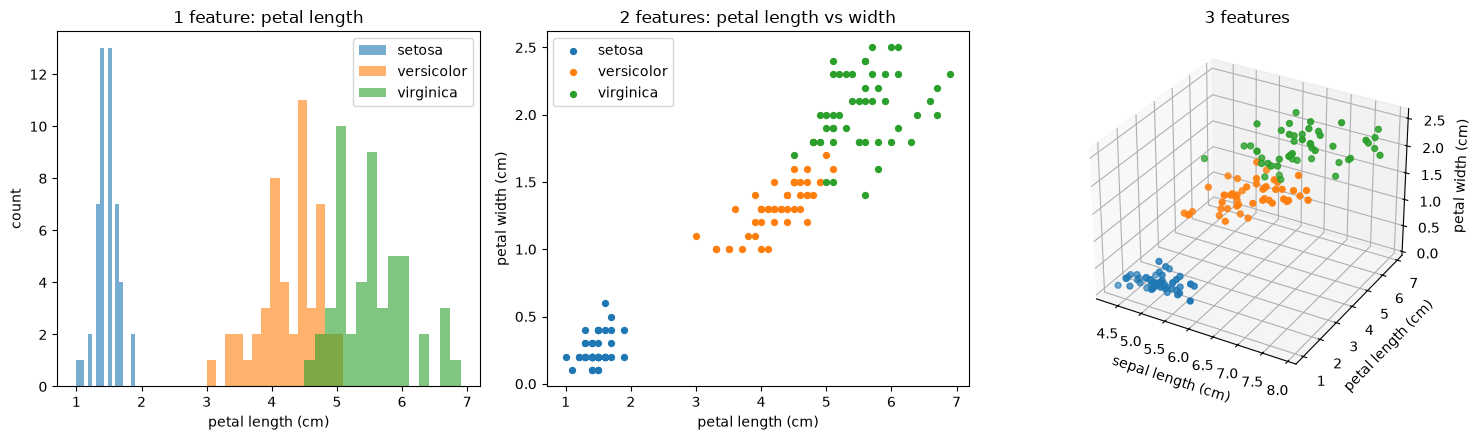

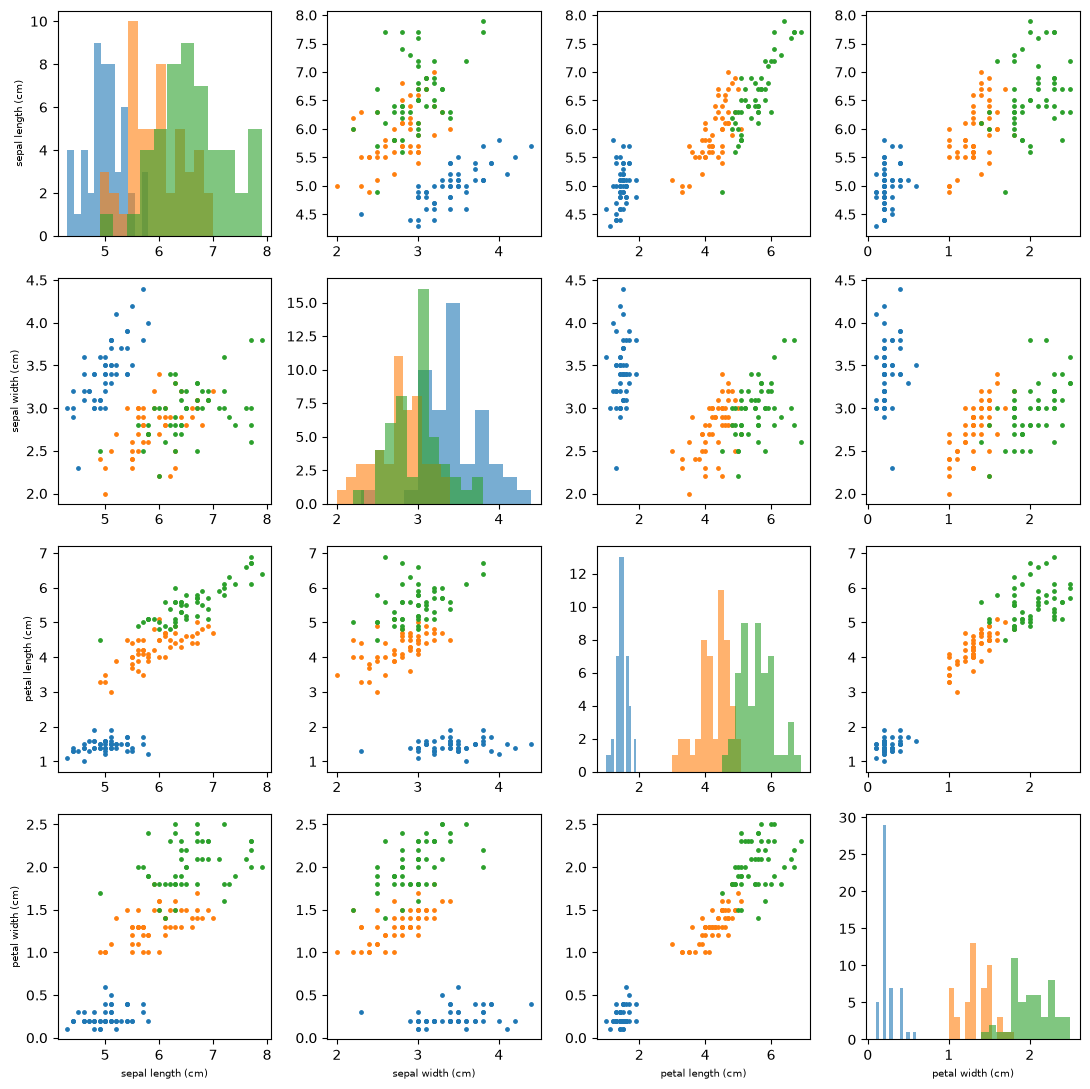

In [23]:
iris = load_iris()
X, y = iris.data, iris.target
names = iris.feature_names
classes = iris.target_names
colors = ["tab:blue", "tab:orange", "tab:green"]

fig = plt.figure(figsize=(15, 4.5))

# 1 feature: petal length (project onto one axis, drop the other 3)
ax = fig.add_subplot(1, 3, 1)
for k in range(3):
    ax.hist(X[y == k, 2], bins=15, alpha=0.6, color=colors[k], label=classes[k])
ax.set_xlabel(names[2]); ax.set_ylabel("count")
ax.set_title("1 feature: petal length"); ax.legend()

# 2 features: petal length vs petal width
ax = fig.add_subplot(1, 3, 2)
for k in range(3):
    ax.scatter(X[y == k, 2], X[y == k, 3], c=colors[k], s=18, label=classes[k])
ax.set_xlabel(names[2]); ax.set_ylabel(names[3])
ax.set_title("2 features: petal length vs width"); ax.legend()

# 3 features: sepal length, petal length, petal width
ax = fig.add_subplot(1, 3, 3, projection="3d")
for k in range(3):
    ax.scatter(X[y == k, 0], X[y == k, 2], X[y == k, 3], c=colors[k], s=18)
ax.set_xlabel(names[0]); ax.set_ylabel(names[2]); ax.set_zlabel(names[3])
ax.set_title("3 features")

plt.tight_layout()
plt.show()

# Extra: every 1D and 2D marginal, to compare which ones cluster well
fig, axes = plt.subplots(4, 4, figsize=(11, 11))
for i in range(4):
    for j in range(4):
        a = axes[i, j]
        if i == j:
            for k in range(3):
                a.hist(X[y == k, i], bins=12, alpha=0.6, color=colors[k])
        else:
            for k in range(3):
                a.scatter(X[y == k, j], X[y == k, i], c=colors[k], s=6)
        if i == 3: a.set_xlabel(names[j], fontsize=7)
        if j == 0: a.set_ylabel(names[i], fontsize=7)
plt.tight_layout()
plt.show()